# Three-month spatiotemporal follow-up — stronger XGBoost screen

This is the **larger follow-up** to the 650-home October shotgun: September–November 2025, all validation homes in each month, up to 40,000 historical training sales per monthly fold, and 500 trees per XGBoost training fit. Start in 2022 so the 730-day age filter can meaningfully differ from the legacy selection.

**Candidates, independently compared against the same baseline:**
- Baseline: 47-term Binary BoW XGBoost + original comparables.
- Feature changes: same-type quota, age-first, both.
- Residual corrections of the baseline: kNN, RBF Ridge, tensor-spline GAM approximation.

Residual models use **three earlier out-of-time calibration folds for each prediction month**; they do *not* learn residuals on the scored homes. These are still exploratory models: October 2025 was already used to choose the shortlist, and scores cannot be directly compared with the 7.82% 700-tree/full-history benchmark.

Each month has a separate folder and can be resumed after completion without redoing prior complete months. Partial or failed model runs are never silently included in pooled results. Your production `model_run.ipynb` and model defaults are untouched.

### Run after pulling main

```powershell
git pull origin main
uv sync
uv run python -m pytest tests/test_spacetime_three_month.py -q
uv run jupyter lab
```

You can also execute the same benchmark in a terminal:
```powershell
uv run python spacetime_three_month.py
```


In [1]:
# Locate the checkout from Jupyter/VS Code, including nested notebook folders.
from pathlib import Path
import os
import sys
_start = Path(os.environ.get("DATA_DASH_ROOT", Path.cwd())).expanduser().resolve()
ROOT = next((p for p in (_start, *_start.parents)
             if (p / "data.py").is_file() and (p / "models").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DATA_DASH_ROOT to your Data Dash checkout before running this notebook.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from IPython.display import display
from spacetime_three_month import run_three_month, MONTHS, FEATURES, RESIDUALS

TRAIN_START = "2022-01-01"
TRAIN_CAP = 40000
TREES = 500
VALIDATION_CAP = 1_000_000   # effectively: every home in each month
CALIBRATION_CAP = 1200
CALIBRATION_FOLDS = 3
BOOTSTRAP_REPEATS = 500
SEED = 42

FEATURE_VARIANTS = (
    "baseline",
    "spacetime_splines",
    "comp_type_quota",
    "comp_both",
    "combined",
    "geo_context",
)

RESIDUAL_VARIANTS = ()

OUTPUT_DIR = "outputs/spacetime_feature_shortlist"

print("Months:", MONTHS)
print("Feature variants:", FEATURE_VARIANTS)
print("Residual variants:", RESIDUAL_VARIANTS)
print("Sample cap:", TRAIN_CAP, "| trees:", TREES)

Months: ('2025-09', '2025-10', '2025-11')
Feature variants: ('baseline', 'spacetime_splines', 'comp_type_quota', 'comp_both', 'combined', 'geo_context')
Residual variants: ()
Sample cap: 40000 | trees: 500


In [2]:
pooled, monthly, by_type, predictions = run_three_month(
    months=MONTHS,
    train_start=TRAIN_START,
    train_cap=TRAIN_CAP,
    trees=TREES,
    validation_cap=VALIDATION_CAP,
    calibration_cap=CALIBRATION_CAP,
    calibration_folds=CALIBRATION_FOLDS,
    features=FEATURE_VARIANTS,
    residuals=RESIDUAL_VARIANTS,
    seed=SEED,
    bootstrap_repeats=BOOTSTRAP_REPEATS,
    output_dir=OUTPUT_DIR,
    resume=True,
)
display(pooled)
display(monthly)


=== 2025-09: enlarged chronological experiment ===
Shotgun: 40,000 historical sales; 2,035 unseen 2025-09 homes; 500 trees per XGBoost
  feature  baseline              MdAPE 9.235% MAPE 11.959% (ΔMdAPE +0.000pp)
  feature  spacetime_splines     MdAPE 8.877% MAPE 11.338% (ΔMdAPE -0.358pp)
  feature  comp_type_quota       MdAPE 9.356% MAPE 11.841% (ΔMdAPE +0.121pp)
  feature  comp_both             MdAPE 9.170% MAPE 11.943% (ΔMdAPE -0.065pp)
  feature  combined              MdAPE 8.933% MAPE 11.576% (ΔMdAPE -0.302pp)
  feature  geo_context           MdAPE 8.916% MAPE 11.660% (ΔMdAPE -0.319pp)

Ranked screen (lower is better):
  homes      mape    mdape  median_signed     arm           variant  delta_mdape_pp  delta_mape_pp
  2035 11.337654 8.876903       1.635861 feature spacetime_splines       -0.358111      -0.621412
  2035 11.660409 8.915597       1.560699 feature       geo_context       -0.319418      -0.298657
  2035 11.575888 8.932983       1.042612 feature          combined       

,homes,mape,mdape,median_signed,arm,variant,delta_mdape_pp,delta_mape_pp,mean_paired_ape_delta,homes_improved_fraction,delta_mdape_ci_low,delta_mdape_ci_high,delta_mape_ci_low,delta_mape_ci_high,months_better_mdape
0,6152,11.265805,8.604483,1.680824,feature,spacetime_splines,-0.555116,-0.595632,-0.595632,0.550553,-0.774337,-0.312497,-0.713710,-0.479979,3
1,6152,11.555550,8.963948,1.506086,feature,geo_context,-0.195651,-0.305886,-0.305886,0.532997,-0.426041,0.019037,-0.408752,-0.197638,2
2,6152,11.565765,8.989150,1.148703,feature,combined,-0.170450,-0.295671,-0.295671,0.515280,-0.381285,0.080640,-0.432373,-0.147847,2
3,6152,11.861436,9.159600,1.620275,feature,baseline,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0
4,6152,11.831066,9.183181,1.540296,feature,comp_both,0.023581,-0.030370,-0.030370,0.492035,-0.208754,0.241883,-0.195324,0.123761,2
5,6152,11.865075,9.306083,1.897563,feature,comp_type_quota,0.146483,0.003638,0.003638,0.491385,-0.093819,0.370291,-0.136625,0.132557,0


,homes,mape,mdape,median_signed,month,arm,variant,delta_mdape_pp,delta_mape_pp
0,2035,11.337654,8.876903,1.635861,2025-09,feature,spacetime_splines,-0.358111,-0.621412
1,2035,11.660409,8.915597,1.560699,2025-09,feature,geo_context,-0.319418,-0.298657
2,2035,11.575888,8.932983,1.042612,2025-09,feature,combined,-0.302032,-0.383178
3,2035,11.942719,9.169683,1.614255,2025-09,feature,comp_both,-0.065332,-0.016347
4,2035,11.959066,9.235015,1.406775,2025-09,feature,baseline,0.000000,0.000000
5,2035,11.841150,9.355718,1.897462,2025-09,feature,comp_type_quota,0.120704,-0.117916
6,2250,10.992068,8.604483,0.100828,2025-10,feature,spacetime_splines,-0.476834,-0.496638
7,2250,11.191798,8.773030,-0.310185,2025-10,feature,combined,-0.308287,-0.296908
8,2250,11.134190,8.804944,-0.175868,2025-10,feature,geo_context,-0.276374,-0.354516
9,2250,11.399419,8.997157,-0.782165,2025-10,feature,comp_both,-0.084160,-0.089287


In [3]:
# Evaluate consistency across three chronological months.
columns = [
    "arm", "variant", "homes", "mdape", "mape",
    "delta_mdape_pp", "delta_mape_pp", "months_better_mdape",
    "homes_improved_fraction",
    "delta_mdape_ci_low", "delta_mdape_ci_high",
]
display(pooled[columns])

# Individual monthly deltas help guard against a one-month fluke.
monthly_delta = monthly.pivot_table(
    index=["arm", "variant"], columns="month",
    values="delta_mdape_pp",
)
display(monthly_delta.round(3))
print("Intervals pair-resample properties; they do not capture all market-month dependence.")

,arm,variant,homes,mdape,mape,delta_mdape_pp,delta_mape_pp,months_better_mdape,homes_improved_fraction,delta_mdape_ci_low,delta_mdape_ci_high
0,feature,spacetime_splines,6152,8.604483,11.265805,-0.555116,-0.595632,3,0.550553,-0.774337,-0.312497
1,feature,geo_context,6152,8.963948,11.555550,-0.195651,-0.305886,2,0.532997,-0.426041,0.019037
2,feature,combined,6152,8.989150,11.565765,-0.170450,-0.295671,2,0.515280,-0.381285,0.080640
3,feature,baseline,6152,9.159600,11.861436,0.000000,0.000000,0,0.000000,0.000000,0.000000
4,feature,comp_both,6152,9.183181,11.831066,0.023581,-0.030370,2,0.492035,-0.208754,0.241883
5,feature,comp_type_quota,6152,9.306083,11.865075,0.146483,0.003638,0,0.491385,-0.093819,0.370291


month                      2025-09  2025-10  2025-11
arm     variant                                     
feature baseline             0.000    0.000    0.000
        combined            -0.302   -0.308    0.162
        comp_both           -0.065   -0.084    0.396
        comp_type_quota      0.121    0.091    0.219
        geo_context         -0.319   -0.276    0.071
        spacetime_splines   -0.358   -0.477   -0.882

Intervals pair-resample properties; they do not capture all market-month dependence.


,homes,mape,mdape,median_signed,house_type_name,arm,variant,delta_mdape_pp,delta_mape_pp
0,39,15.425,11.193,6.379,Co-Op Apt,feature,comp_both,-0.727,0.894
1,39,14.531,11.920,3.111,Co-Op Apt,feature,baseline,0.000,0.000
2,39,14.140,12.177,1.929,Co-Op Apt,residual,knn,0.257,-0.390
3,39,14.225,12.298,3.003,Co-Op Apt,residual,tensor_gam,0.378,-0.306
4,39,14.062,12.342,2.449,Co-Op Apt,residual,rbf_ridge,0.422,-0.468
5,39,15.328,12.678,3.707,Co-Op Apt,feature,comp_age_first,0.758,0.798
6,39,16.074,13.230,5.235,Co-Op Apt,feature,comp_type_quota,1.311,1.543
7,2732,10.878,8.197,1.353,Condo Apt,feature,comp_age_first,-0.191,0.055
8,2732,10.707,8.238,0.888,Condo Apt,residual,tensor_gam,-0.150,-0.116
9,2732,10.709,8.241,0.689,Condo Apt,residual,rbf_ridge,-0.147,-0.113


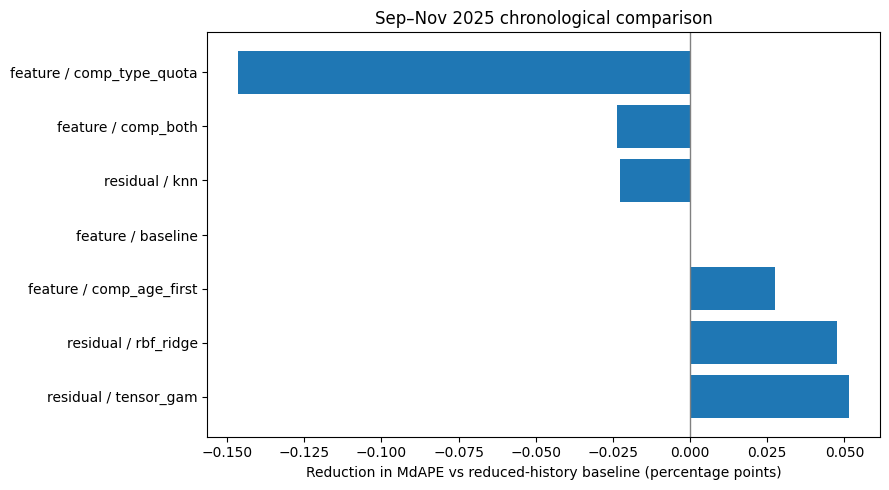

In [4]:
# Property-type diagnostics; each group has at least 20 homes.
if not by_type.empty:
    display(by_type.sort_values(["house_type_name", "mdape"]).round(3))
else:
    print("No sufficiently large property-type groups in these rows.")

# Optional visual: bars show improvement relative to baseline.
import matplotlib.pyplot as plt
ranking = pooled.sort_values("delta_mdape_pp")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    ranking["arm"] + " / " + ranking["variant"],
    -ranking["delta_mdape_pp"],
)
ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel("Reduction in MdAPE vs reduced-history baseline (percentage points)")
ax.set_title("Sep–Nov 2025 chronological comparison")
fig.tight_layout()
plt.show()

## How to interpret the second-stage results

- Judge both **pooled MdAPE and MAPE**, not just a single good subgroup.
- Prefer candidates with improvements over **multiple months**, not a very large win in one month.
- The bootstrap intervals describe paired uncertainty **conditional on these three months**, not uncertainty about a future housing market.
- **Age-first may now differ** because January 2022–2025 transactions are eligible for the training sample, including sales older than 730 days.
- Residual corrections are based on the **original comparable model**, not on the type-quota model. Combining them is a separate experiment requiring recalibration of the residual targets.
- After this, run the winning *feature change* through the full `model_run.ipynb` with 700 trees and the full historical training set. A winning *residual method* needs a deployment-ready chronological calibration pipeline before final confirmation.

Output files:
- `outputs/spacetime_three_month/pooled_summary.csv`
- `outputs/spacetime_three_month/monthly_summary.csv`
- `outputs/spacetime_three_month/house_type_summary.csv`
- `outputs/spacetime_three_month/predictions.csv`
- Three month-specific folders, supporting reuse/resume

The benchmark does **not** append speculative or unverified entries to `logs.md`.